# Final Delta production: GEVP 2pt → gluon 3pt (method 1) → ratio → fits, at one (frame, q), forward or off-forward

Input, for the `frame` and `q` set in the settings: the per-q 2pt files of `delta_package_byq.py` (C3input: the 2pt weighted with $e^{-iq\cdot x_{\rm src}}$, the input of the 3pt; C2pf and C2pi: the plain 2pt at $p_f$ and at $p_i = p_f - q$; at q = 0 one file is all three) and the per-q HYP FF file of `packFF_byq.py` (all 96 time slices).

1. **GEVP**: per half (forward, backward) the GEVP of the source-averaged operator matrix of C2pf and of C2pi; the 2pts are reconstructed with the ground-state vectors at `t_ref`: C2pf with $v_0(p_f)$, C2pi with $v_0(p_i)$, C3input with $v_0(p_f)$ at the sink and $v_0(p_i)$ at the source.
2. **3pt, method 1**: connected $\langle C_2\,O\rangle$ minus $\langle C_2\rangle\langle O\rangle$ per jackknife replicate, forward and backward, saved.
3. **Ratio**: $R = \mathrm{Re}\,C_3 / C_2(p_f)$ times a square root of 2pts at $p_f$ and $p_i$, for forward, backward and their average (fb), saved with plots.
3b. **Average over equivalent q** (optional): after sections 1-3 have run at every q of `q_average_list`, the ratio and the 2pts are averaged over these q, replicate by replicate, and section 4 fits the average.
4. **Fits**: the 2pt fit at every $p_f$ and $p_i$ for the gap priors (same model as `2PT_simple/2pt_fit_packagecode.py`) and the ratio fit (same model as `fit_ratio_hyp.py`).

**q = 000** is the forward case: `frame = "forward"`, `q = [0, 0, 0]`, with the files of `delta_package_byq.py` (`pack_list = [["forward", [0, 0, 0]]]`: one file that serves as C3input, C2pf and C2pi) and of `packFF_byq.py` (`q_pack_list = [[0, 0, 0]]`). Then $p_f = p_i$, the same $v_0$ sits at sink and source, the square root of the ratio is 1, and every step is the forward analysis of `gevp_3pt_ratio_fit_final.ipynb`.

Everything is written to `out_dir` = `final_production/{frame}_q{qx}_{qy}_{qz}`, and every file name has `{frame}_q{qx}_{qy}_{qz}`. Each section reads what the one before saved, so after the settings cell any section can be rerun alone.

In [3]:
#======== settings, used by every section ========
import os
import re
import json
import glob
import h5py
import numpy as np
import matplotlib.pyplot as plt
from opt_einsum import contract

here = "/Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta"
pack_dir = here                                             # per-q 2pt files (delta_package_byq.py): C3input, C2pf, C2pi
FF_dir = here                                               # per-q FF files (packFF_byq.py)

hadron = "pion"                                             # "pion" or "proton"
frame = "sym"                                               # "forward" (q = 0), "sym" or "asy", as in delta_package_byq.py
q = [0, -2, 0]                                               # momentum transfer in units of 2pi/L: P_f = P_i + q
q_average_list = [[2, 0, 0], [-2, 0, 0], [0, 2, 0], [0, -2, 0]]   # section 3b: equivalent q of this frame to average, each run through sections 1-3 first

#GEVP basis (section 1): smear 0 = [4.5, 2.25, 0.8], 1 = [1.5, 1.5, 0];  gamma 0 = G5, 1 = G5G4, 2 = G3G5
smear_use = [0, 1]
gamma_use = [0,1,2]
t0 = 2                                                      # GEVP reference time
t_ref = 4                                                   # time of the ground-state vector v0 that reconstructs the 2pt
phase_ref = (1, 0)                                          # (smear, gamma) whose ground-state overlap is real and positive at every momentum: [1.5, 1.5] G5, no boost
c_sign = {"pion": -1, "proton": +1}[hadron]                 # the pion comes out negative (the fermion-loop sign is not in the code), the projected proton positive
m_had = {"pion": 0.141, "proton": 0.51}[hadron]             # dispersion line only; proton: 6x6 GEVP at pz = 0, t = 8..11 (look_packed_final.py)

operator = "TXTXpTYTYm2XYXY"                                # the operator of the ratio and the fits (sections 3, 4)
Ls, Lt = 32, 96
op_names = ["TXTX", "TYTY", "XYXY", "TXTXpTYTY", "TXTXpTYTYm2XYXY", "TXTXpTYTYp2XYXY"]


def jk(data, jk_axis=0):
    n = data.shape[jk_axis]
    data = np.moveaxis(data, jk_axis, 0)
    mean = np.mean(data, axis=0)
    err = np.sqrt((n - 1.0) / n * np.sum((data - mean) ** 2, axis=0))
    return mean, err


def jackknife(x):
    n_cfg = x.shape[0]
    return (x.sum(axis=0) - x) / (n_cfg - 1)


def text(values):
    return [v.decode() if isinstance(v, bytes) else str(v) for v in values]


def ncfg_of(name):
    return int(name.split("_ncfg")[1].split("_")[0].split(".")[0])


#file names shared by the sections: everything of this (frame, q) goes to its own folder and has kin_tag in its name
q_tag = f"q{q[0]}_{q[1]}_{q[2]}"
kin_tag = f"{frame}_{q_tag}"
out_dir = f"{here}/final_production/{kin_tag}"              # everything this notebook writes
pack_file = {}
for role in ["C3input", "C2pf", "C2pi"]:                    # at q = 0 (forward) the C3input file is also the C2pf and the C2pi file
    found = glob.glob(f"{pack_dir}/2pt_*_GEVP_{kin_tag}_{'C3input' if frame == 'forward' else role}_*_{hadron}{'_projected' if hadron == 'proton' else ''}.h5")
    assert found, f"no {role} file of the {hadron} at {kin_tag} in {pack_dir}"
    pack_file[role] = max(found, key=ncfg_of)               # the file with the most cfgs
found = glob.glob(f"{FF_dir}/FF_hyp*_{q_tag}_ncfg*.h5")
assert found, f"no FF file at {q_tag} in {FF_dir}"
FF_path = max(found, key=ncfg_of)
cfg_lists = {}
for role in pack_file:
    with h5py.File(pack_file[role], "r") as f:
        cfg_lists[role] = f["cfg_list"][:]
        assert f["q"][:].tolist() == q and f.attrs["frame"] == frame, f"{pack_file[role]} is not ({frame}, q = {q})"
assert all(np.array_equal(cfg_lists[role], cfg_lists["C3input"]) for role in cfg_lists), "the C3input, C2pf and C2pi files hold different cfgs"
n_cfg = len(cfg_lists["C3input"])
n_src = int(re.search(r"_(\d+)src_", pack_file["C3input"]).group(1))
with h5py.File(FF_path, "r") as f:
    hyp_tag = f"{f['hyp_list'][0]}-{f['hyp_list'][-1]}"
basis_tag = "smear" + "".join(str(s) for s in smear_use) + "_gamma" + "".join(str(g) for g in gamma_use)
pt2_tag = f"{basis_tag}_t0{t0}_tref{t_ref}"
run_tag = f"{n_src}src_ncfg{n_cfg}"
rec_path = f"{out_dir}/2pt_reconstructed_{hadron}_{kin_tag}_{pt2_tag}_{run_tag}.h5"
pt3_path = {d: f"{out_dir}/pt3_jk_method1_{hadron}_{kin_tag}_gevp_{pt2_tag}_{d}_hyp{hyp_tag}_{run_tag}.h5" for d in ("forward", "backward")}
ratio_dir = f"{out_dir}/ratio_data"
plot_dir = f"{out_dir}/plots"
def ratio_path(d):
    return f"{ratio_dir}/ratio_method1_{hadron}_{kin_tag}_gevp_{pt2_tag}_{d}_{operator}_hyp{hyp_tag}_{run_tag}.h5"
for folder in [out_dir, ratio_dir, plot_dir]:
    os.makedirs(folder, exist_ok=True)
print(f"{hadron}, {kin_tag}: {n_cfg} cfgs")
for role in pack_file:
    print(f"  {role}: {os.path.basename(pack_file[role])}")
print(f"  FF: {os.path.basename(FF_path)}")
print(f"GEVP basis {basis_tag}, t0 = {t0}, t_ref = {t_ref};  output in {out_dir}")

pion, sym_q0_-2_0: 91 cfgs
  C3input: 2pt_coulomb_rho4p5z2p25-rho1p5_frac0p8-0_paired_GEVP_sym_q0_-2_0_C3input_fb_tsep20_3072src_ncfg91_pion.h5
  C2pf: 2pt_coulomb_rho4p5z2p25-rho1p5_frac0p8-0_paired_GEVP_sym_q0_-2_0_C2pf_fb_tsep20_3072src_ncfg91_pion.h5
  C2pi: 2pt_coulomb_rho4p5z2p25-rho1p5_frac0p8-0_paired_GEVP_sym_q0_-2_0_C2pi_fb_tsep20_3072src_ncfg91_pion.h5
  FF: FF_hyp0-8_w0-9_q0_-2_0_ncfg200.h5
GEVP basis smear01_gamma012, t0 = 2, t_ref = 4;  output in /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/final_production/sym_q0_-2_0


## 1. GEVP: reconstructed 2pt

Per half the source-averaged matrix $C(t)$ of the basis (hermitian part, sign `c_sign`), of C2pf and of C2pi; GEVP $C(t)v = \lambda C(t_0) v$ on its mean; $v_0$ = ground-state vector at `t_ref`, normalized to $v_0^\dagger C(t_0) v_0 = 1$. Its phase is fixed so that $(C(t_0)v_0)_a$ is real and positive for the `phase_ref` operator $a$ at every momentum: the phase cancels in $v_0^\dagger C v_0$ but not in C3input, which has $v_0(p_f)$ at the sink and $v_0(p_i)$ at the source. The 2pts of every cfg and t_src: C2pf = `c_sign` $v_0(p_f)^\dagger C v_0(p_f)$, C2pi = `c_sign` $v_0(p_i)^\dagger C v_0(p_i)$, C3input = `c_sign` $v_0(p_f)^\dagger C v_0(p_i)$, with that half's vectors (the same for every cfg). The proton is projected to positive parity first: forward $\mathrm{tr}[P_+ M]$, backward $-\mathrm{tr}[P_- M]$.

basis 6x6: ['rho4p5z2p25 G5', 'rho4p5z2p25 G5G4', 'rho4p5z2p25 G3G5', 'rho1p5 G5', 'rho1p5 G5G4', 'rho1p5 G3G5'] (checked against the files)
pt2 shape (cfg, op_snk, op_src, t_src, pz, tsep): (91, 6, 6, 24, 7, 20)
C2pf forward: max over pz of |<C_rec(t0)> - 1| = 2.1e-15
C2pi forward: max over pz of |<C_rec(t0)> - 1| = 3.6e-15
C2pf backward: max over pz of |<C_rec(t0)> - 1| = 2.3e-15
C2pi backward: max over pz of |<C_rec(t0)> - 1| = 3.1e-15
C2pf p = (0, -1, 0): reconstructed meff t = 4..10  0.2606(0.0005) 0.2539(0.0005) 0.2499(0.0005) 0.2484(0.0006) 0.2446(0.0006) 0.2444(0.0006) 0.2447(0.0007)
C2pf p = (0, -1, 1): reconstructed meff t = 4..10  0.3363(0.0005) 0.3277(0.0006) 0.3227(0.0006) 0.3203(0.0007) 0.3158(0.0007) 0.3147(0.0009) 0.3146(0.0009)
C2pf p = (0, -1, 2): reconstructed meff t = 4..10  0.4957(0.0006) 0.4852(0.0007) 0.4776(0.0009) 0.4746(0.0012) 0.4685(0.0014) 0.4649(0.0019) 0.4612(0.0024)
C2pf p = (0, -1, 3): reconstructed meff t = 4..10  0.6754(0.0006) 0.6644(0.0009) 0.6551(0

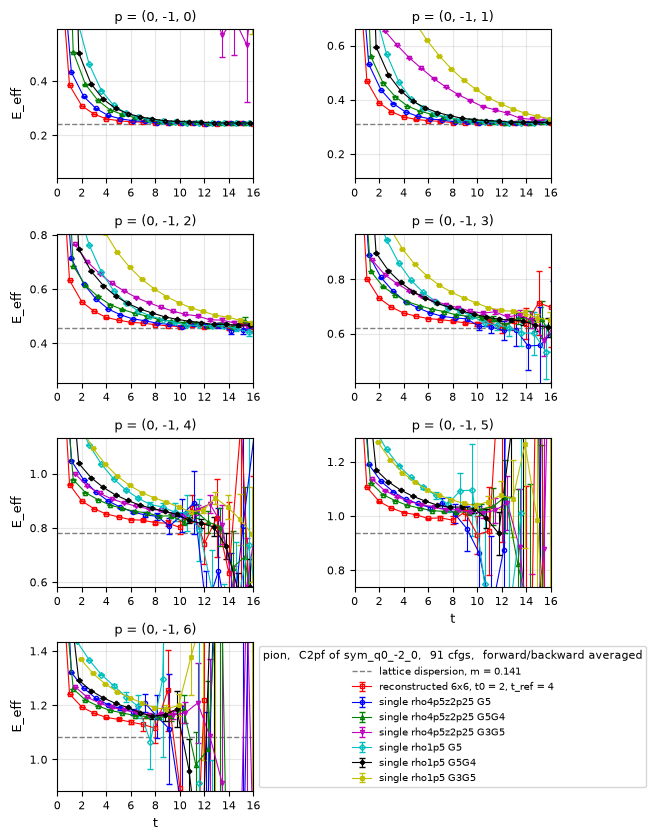

C2pi p = (0, 1, 0): reconstructed meff t = 4..10  0.2608(0.0005) 0.2538(0.0005) 0.2499(0.0005) 0.2484(0.0006) 0.2446(0.0006) 0.2443(0.0007) 0.2446(0.0007)
C2pi p = (0, 1, 1): reconstructed meff t = 4..10  0.3367(0.0006) 0.3282(0.0006) 0.3234(0.0006) 0.3213(0.0008) 0.3161(0.0007) 0.3162(0.0009) 0.3163(0.0010)
C2pi p = (0, 1, 2): reconstructed meff t = 4..10  0.4958(0.0006) 0.4857(0.0007) 0.4785(0.0008) 0.4746(0.0012) 0.4681(0.0014) 0.4697(0.0017) 0.4638(0.0026)
C2pi p = (0, 1, 3): reconstructed meff t = 4..10  0.6751(0.0007) 0.6638(0.0009) 0.6560(0.0013) 0.6518(0.0025) 0.6523(0.0035) 0.6477(0.0052) 0.6463(0.0093)
C2pi p = (0, 1, 4): reconstructed meff t = 4..10  0.8509(0.0007) 0.8408(0.0010) 0.8353(0.0020) 0.8270(0.0041) 0.8323(0.0068) 0.8121(0.0106) 0.8422(0.0260)
C2pi p = (0, 1, 5): reconstructed meff t = 4..10  1.0125(0.0008) 1.0033(0.0014) 0.9963(0.0027) 0.9791(0.0064) 1.0025(0.0122) 0.9505(0.0303) 1.0686(0.0737)
C2pi p = (0, 1, 6): reconstructed meff t = 4..10  1.1555(0.0015) 1.150

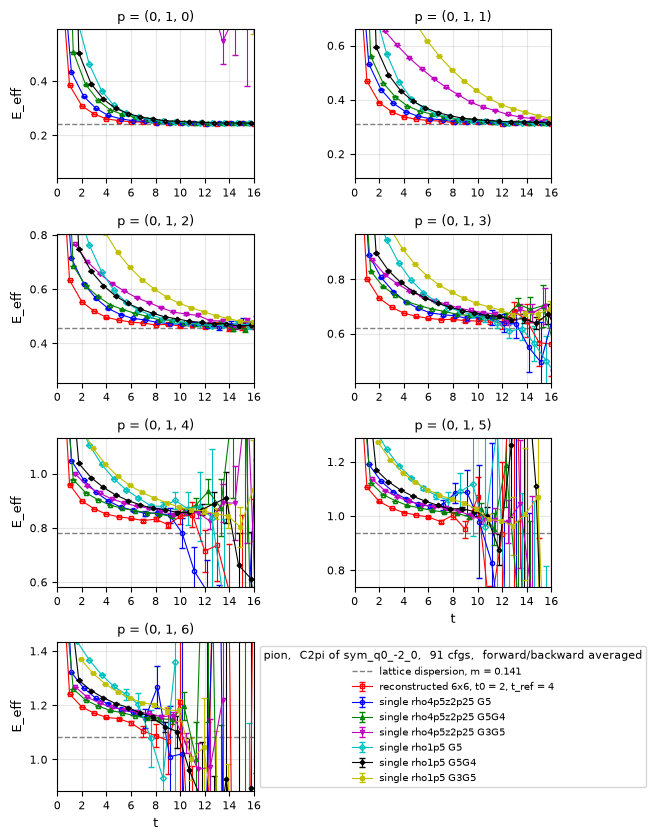

saved /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/final_production/sym_q0_-2_0/2pt_reconstructed_pion_sym_q0_-2_0_smear01_gamma012_t02_tref4_3072src_ncfg91.h5


In [4]:
#======== 1. GEVP: reconstructed 2pt per cfg and t_src ========
def solve_gevp(C_matrix):
    eigen_val = np.full((n_pf, n_op, len(t_list)), np.nan)
    eigen_vec = np.full((n_pf, n_op, len(t_list), n_op), np.nan, "<c16")
    for ipf in range(n_pf):
        L = np.linalg.cholesky(C_matrix[:, :, ipf, t0])
        L_inv = np.linalg.inv(L)
        for it, t in enumerate(t_list):
            M = L_inv @ C_matrix[:, :, ipf, t] @ L_inv.conj().T
            w, u = np.linalg.eigh(M)
            v = L_inv.conj().T @ u
            order = np.argsort(w)[::-1]
            eigen_val[ipf, :, it] = w[order]
            eigen_vec[ipf, :, it] = v[:, order].T
    return eigen_val, eigen_vec


def read_basis(path):
    #one per-q 2pt file as the operator matrix of the basis, per half: (cfg, op_snk, op_src, t_src, pz, tsep), operator a = n_gamma * i_smear + i_gamma
    with h5py.File(path, "r") as f:
        pt2 = {}
        for half in ["forward", "backward"]:
            if hadron == "proton" and "dirac_sink" in f.attrs["dim_pt2"]:   # open Dirac indices: positive parity, one cfg at a time (these files are several GB); _projected files are read as they are
                proj = f["parity_p"][:] if half == "forward" else -f["parity_m"][:]
                pt2[half] = np.stack([np.einsum("kl,abcdlktpT->abcdtpT", proj, f[f"pt2_{half}"][ic]) for ic in range(n_cfg)])
            else:
                pt2[half] = f[f"pt2_{half}"][:]
    matrix = {}
    for half in pt2:
        x = pt2[half][:, smear_use][:, :, smear_use][:, :, :, gamma_use][:, :, :, :, gamma_use]
        matrix[half] = x.transpose(0, 1, 3, 2, 4, 5, 6, 7).reshape(n_cfg, n_op, n_op, n_tsrc, n_pf, tsep_max)
        for a, (s_snk, g_snk) in enumerate(op_pairs):
            for b, (s_src, g_src) in enumerate(op_pairs):
                assert np.array_equal(matrix[half][:, a, b], pt2[half][:, s_snk, s_src, g_snk, g_src]), f"{path}: operator pair ({a}, {b}) does not match the file"
    return matrix


#---- the per-q files: (cfg, smear_snk, smear_src, g_snk, g_src, [dirac_snk, dirac_src,] t_src, pz, tsep); C3input p_i -> p_f, C2pf at p_f, C2pi at p_i
with h5py.File(pack_file["C3input"], "r") as f:
    cfg_list = f["cfg_list"][:]
    t_src_list = f["t_src_list"][:]                         # (cfg, t_src)
    pf_list = f["pf_list"][:]                               # (pz, 3): p_f
    pi_list = f["pi_list"][:]                               # (pz, 3): p_i = p_f - q
    smear_list = f["smear_list"][:]
    smear_names = text(f["smear_names"][:])
    gamma_list = text(f.attrs["gamma_list"])
    n_tsrc, n_pf, tsep_max = f["pt2_forward"].shape[-3:]
momenta = {"C2pf": pf_list, "C2pi": pi_list}
for role in momenta:
    with h5py.File(pack_file[role], "r") as f:
        assert np.array_equal(f["momentum_list"][:], momenta[role]), f"{role}: momenta {f['momentum_list'][:].tolist()} are not {momenta[role].tolist()}"
        assert np.array_equal(f["t_src_list"][:], t_src_list), f"{role}: t_src differ from the C3input file"

n_smear, n_gamma = len(smear_use), len(gamma_use)
n_op = n_smear * n_gamma
op_pairs = [(s, g) for s in smear_use for g in gamma_use]                  # same order as the operator index
op_labels = [f"{smear_names[s]} {gamma_list[g]}" for s, g in op_pairs]
pt2_matrix = {}
for role in pack_file:
    same = [r for r in pt2_matrix if pack_file[r] == pack_file[role]]
    pt2_matrix[role] = pt2_matrix[same[0]] if same else read_basis(pack_file[role])      # forward: one file for all three
print(f"basis {n_op}x{n_op}:", op_labels, "(checked against the files)")
print("pt2 shape (cfg, op_snk, op_src, t_src, pz, tsep):", pt2_matrix["C3input"]["forward"].shape)

#---- GEVP per half on the mean of C2pf (vector at p_f, used at the sink) and of C2pi (vector at p_i, used at the source)
#     Phase of v0: the eigenvector's phase is arbitrary. It cancels in v0^dag C v0, but not in C3input, which has v0(p_f) at the sink and v0(p_i) at the
#     source. It is fixed by making (C(t0) v0)[a_ref] = Z0[a_ref] (Z0^dag v0) e^{-E0 t0} real and positive at every momentum, i.e. the overlap of the
#     phase_ref operator with the ground state is taken real and positive, and then so is Z0^dag v0.
assert phase_ref in op_pairs, f"phase_ref {phase_ref} is not in the basis {op_pairs}"
a_ref = op_pairs.index(phase_ref)
t_list = np.arange(t0 + 1, tsep_max)
it_ref = list(t_list).index(t_ref)
C, v0 = {}, {}
for role in momenta:
    for half in ["forward", "backward"]:
        C_half = pt2_matrix[role][half].mean(axis=3)                        # (cfg, op, op, pz, tsep): mean over t_src
        C[role, half] = c_sign * 0.5 * (C_half + np.conj(np.swapaxes(C_half, 1, 2)))      # hermitian part
        assert (np.einsum("aapt->apt", C[role, half].mean(axis=0))[:, :, t0].real > 0).all(), f"{role} {half}: diagonal of C(t0) is not positive, check c_sign for {hadron}"
        eigen_val, eigen_vec = solve_gevp(C[role, half].mean(axis=0))
        v0[role, half] = eigen_vec[:, 0, it_ref, :]                         # (pz, op)
        Cv = np.einsum("abp,pb->pa", C[role, half].mean(axis=0)[:, :, :, t0], v0[role, half])     # (pz, op): C(t0) v0
        v0[role, half] = v0[role, half] * (np.abs(Cv[:, a_ref]) / Cv[:, a_ref])[:, None]         # now (C(t0) v0)[a_ref] > 0

#---- reconstructed 2pt of every cfg and t_src: (cfg, t_src, pz, tsep); C2pf with v0(p_f), C2pi with v0(p_i), C3input with v0(p_f) at the sink and v0(p_i) at the source
pt2_rec = {}
for half in ["forward", "backward"]:
    for role, v_snk, v_src in [("C2pf", "C2pf", "C2pf"), ("C2pi", "C2pi", "C2pi"), ("C3input", "C2pf", "C2pi")]:
        pt2_rec[role, half] = c_sign * np.einsum("pa,cabtpT,pb->ctpT", np.conj(v0[v_snk, half]), pt2_matrix[role][half], v0[v_src, half])
    for role in momenta:
        deviation = np.abs(pt2_rec[role, half][:, :, :, t0].mean(axis=(0, 1)).real - 1).max()
        print(f"{role} {half}: max over pz of |<C_rec(t0)> - 1| = {deviation:.1e}")
        assert deviation < 1e-10, f"{role} {half}: v0 is not normalized to v0^dag C(t0) v0 = 1"

#---- effective mass: reconstructed 2pt and the diagonals of the basis, mean over t_src, forward/backward averaged; one figure per momentum list
t_meff = np.arange(tsep_max - 1)
for role in (["C2pf"] if frame == "forward" else ["C2pf", "C2pi"]):
    rec_fb = 0.5 * (pt2_rec[role, "forward"].mean(axis=1) + pt2_rec[role, "backward"].mean(axis=1)).real      # (cfg, pz, tsep)
    curves = [(f"reconstructed {n_op}x{n_op}, t0 = {t0}, t_ref = {t_ref}", rec_fb)]
    for a in range(n_op):
        curves.append((f"single {op_labels[a]}", 0.5 * (C[role, "forward"][:, a, a] + C[role, "backward"][:, a, a]).real))
    meff = []
    with np.errstate(invalid="ignore", divide="ignore"):
        for label, c2 in curves:
            mean = np.log(c2.mean(axis=0)[:, :-1] / c2.mean(axis=0)[:, 1:])
            c2_jk = jackknife(c2)
            meff.append((label, mean, jk(np.log(c2_jk[:, :, :-1] / c2_jk[:, :, 1:]))[1]))
    for ip, p in enumerate(momenta[role]):
        print(f"{role} p = {tuple(int(v) for v in p)}: reconstructed meff t = 4..10  " + " ".join(f"{meff[0][1][ip, t]:.4f}({meff[0][2][ip, t]:.4f})" for t in range(4, 11)))

    plt.figure(figsize=(6.5, 8.5))                          # one page in LaTeX: 6.5 in wide, 8.5 in tall
    for ip, p in enumerate(momenta[role]):
        plt.subplot(4, 2, ip + 1)                           # 2 + 2 + 2 + 1 panels, filled row by row
        p_lat = 2 * np.pi * p / Ls
        E_disp = 2 * np.arcsinh(np.sqrt(np.sinh(m_had / 2) ** 2 + np.sum(np.sin(p_lat / 2) ** 2)))
        plt.axhline(E_disp, color="gray", lw=1, ls="--", label=f"lattice dispersion, m = {m_had}")
        for i, (label, mean, err) in enumerate(meff):
            plt.errorbar(t_meff + 0.15 * i, mean[ip], yerr=err[ip], fmt=["rs-", "bo-", "g^-", "mv-", "cD-", "kP-", "yX-"][i % 7],
                         capsize=2, ms=3, mfc="none", lw=0.8, label=label)
        plt.ylim(E_disp - 0.2, E_disp + (0.35 if hadron == "pion" else 0.6))
        plt.xlim(0, 16)
        plt.xticks(np.arange(0, 17, 2), fontsize=8)
        plt.yticks(fontsize=8)
        plt.grid(alpha=0.3)
        plt.title(f"p = ({p[0]}, {p[1]}, {p[2]})", fontsize=9)
        if ip >= len(momenta[role]) - 2:
            plt.xlabel("t", fontsize=9)
        if ip % 2 == 0:
            plt.ylabel("E_eff", fontsize=9)
        if ip == 0:
            handles, labels = plt.gca().get_legend_handles_labels()
    plt.subplot(4, 2, 8)                                    # the empty 8th slot holds the legend
    plt.axis("off")
    plt.legend(handles, labels, loc="center", fontsize=7, title=f"{hadron},  {role} of {kin_tag},  {n_cfg} cfgs,  forward/backward averaged", title_fontsize=8)
    plt.tight_layout()
    plt.savefig(f"{plot_dir}/meff_reconstructed_{hadron}_{kin_tag}_{role}_{pt2_tag}_{run_tag}.pdf")
    plt.show()

#---- save, with the GEVP parameters
with h5py.File(rec_path, "w") as f:
    for role in ["C3input", "C2pf", "C2pi"]:
        for half in ["forward", "backward"]:
            f.create_dataset(f"pt2_{role}_{half}", data=pt2_rec[role, half])        # (cfg, t_src, pz, tsep)
    for role in momenta:
        for half in ["forward", "backward"]:
            f.create_dataset(f"v0_{role}_{half}", data=v0[role, half])             # (pz, op)
    f.create_dataset("cfg_list", data=cfg_list)
    f.create_dataset("t_src_list", data=t_src_list)
    f.create_dataset("q", data=np.array(q))
    f.create_dataset("pf_list", data=pf_list)                               # (pz, 3): p_f
    f.create_dataset("pi_list", data=pi_list)                               # (pz, 3): p_i = p_f - q
    f.create_dataset("smear_use", data=np.array(smear_use))
    f.create_dataset("gamma_use", data=np.array(gamma_use))
    f.create_dataset("smear_list", data=smear_list[smear_use])              # rows [rho_T, rho_z, mom_frac] of the smearings used
    f.create_dataset("operator_labels", data=np.array(op_labels, dtype=h5py.string_dtype()))
    f.attrs["hadron"] = hadron
    f.attrs["frame"] = frame
    f.attrs["dim_pt2"] = "cfg, t_src, pz, tsep"
    f.attrs["dim_v0"] = f"pz, op;  operator a = {n_gamma} * i_smear + i_gamma, i_smear over smear_use, i_gamma over gamma_use"
    f.attrs["t0"] = t0
    f.attrs["t_ref"] = t_ref
    f.attrs["c_sign"] = c_sign
    f.attrs["gevp"] = (f"per half: C(t) = c_sign * hermitian part of the t_src-averaged matrix of the {n_op} operators, of C2pf (at p_f) and of C2pi (at p_i); "
                       f"GEVP C(t) v = lambda C(t0) v on its mean over cfgs (Cholesky of C(t0)); v0 = ground-state vector at t_ref, normalized to v0^dag C(t0) v0 = 1; "
                       f"per cfg and t_src with that half's vectors (the same for every cfg): pt2_C2pf = c_sign v0(p_f)^dag C2pf v0(p_f), "
                       f"pt2_C2pi = c_sign v0(p_i)^dag C2pi v0(p_i), pt2_C3input = c_sign v0(p_f)^dag C3input v0(p_i)")
    f.attrs["v0_phase"] = f"(C(t0) v0)[a] real and positive for operator a = {a_ref} ({op_labels[a_ref]}) at every momentum: its ground-state overlap is taken real and positive"
    f.attrs["proton_projection"] = "forward tr[P+ M], backward -tr[P- M] before the GEVP" if hadron == "proton" else "none (pion)"
    f.attrs["source_files"] = json.dumps(pack_file)
print("saved", rec_path)

## 2. 3pt, method 1

The per-q FF file holds the operator on all 96 time slices; it is read at the 24 source times of the 2pt, $O(t_{\rm src} \pm \tau)$. The centering phase $e^{-i\pi q_z w/L_s}$ moves the Fourier phase from the start of the Wilson line to its middle (1 for $q_z = 0$). Method 1: connected $\langle C_2(t_{\rm src})\,O(t_{\rm src} \pm \tau)\rangle$ averaged over sources, minus $\langle C_2\rangle\langle O\rangle$ per jackknife replicate (for q ≠ 0 both averages are zero up to noise).

In [5]:
#======== 2. 3pt, method 1 ========
#---- reconstructed 3pt input from section 1: (cfg, t_src, pz, tsep), sink at p_f, source at p_i
with h5py.File(rec_path, "r") as f:
    pt2_rec = {d: f[f"pt2_C3input_{d}"][:] for d in ("forward", "backward")}
    cfg_list = f["cfg_list"][:]
    t_src_list = f["t_src_list"][:]
    pf_list = f["pf_list"][:]
    pi_list = f["pi_list"][:]
    pt2_note = f"GEVP {pt2_tag}: " + str(f.attrs["gevp"])
n_cfg, n_tsrc, n_pf, tsep_max = pt2_rec["forward"].shape

#---- the three FF components of the operators on all Lt slices, on the cfgs of the 2pt; FF munu order [XY, YZ, XZ, XT, YT, ZT]
with h5py.File(FF_path, "r") as f:
    assert f["q"][:].tolist() == q, f"the FF file holds q = {f['q'][:].tolist()}, not q = {q}"
    FF_cfg_list = f["cfg_list"][:].tolist()
    hyp_list = f["hyp_list"][:]
    w_list = f["w_list"][:]
    FF_smearing = str(f.attrs["smearing"])
    idx = [FF_cfg_list.index(int(c)) for c in cfg_list]                    # increasing, as h5py needs
    O_full = {name: f["FF"][idx, mu, mu] for name, mu in [("TXTX", 3), ("TYTY", 4), ("XYXY", 0)]}     # (cfg, hyp, w, t)
#centering: the FF line runs from x to x - w z with the Fourier phase at x; centered at x - w z/2 the operator has exp(-i pi q_z w / Ls) more (1 for q_z = 0)
centering = np.exp(-1j * np.pi * q[2] * w_list / Ls)
for name in O_full:
    O_full[name] = O_full[name] * centering[None, None, :, None]
O_full["TXTXpTYTY"] = O_full["TXTX"] + O_full["TYTY"]
O_full["TXTXpTYTYm2XYXY"] = O_full["TXTXpTYTY"] - 2 * O_full["XYXY"]
O_full["TXTXpTYTYp2XYXY"] = O_full["TXTXpTYTY"] + 2 * O_full["XYXY"]

tau = np.arange(tsep_max)                                                   # the 3pt keeps tau = 0 .. tsep_max-1, like tsep
for d, sign in [("forward", +1), ("backward", -1)]:
    #operator at the 2pt source times: O(t_src + tau) forward, O(t_src - tau) backward, (cfg, t_src, hyp, w, tau)
    t_index = (t_src_list[:, :, None] + sign * tau[None, None, :]) % Lt    # (cfg, t_src, tau)
    operators = [np.stack([O_full[name][ic][..., t_index[ic]] for ic in range(n_cfg)]).transpose(0, 3, 1, 2, 4) for name in op_names]

    pt2_src = pt2_rec[d]                                                    # (cfg, t_src, pf, tsep)

    #connected piece
    pt2FF = []
    for op in operators:
        connected_term = contract(pt2_src, ["cfg", "tsrc", "pf", "tsep"],
                                  op,      ["cfg", "tsrc", "hyp", "w", "tau"],
                                           ["cfg", "hyp", "w", "tsep", "tau", "pf"])
        pt2FF.append(connected_term / n_tsrc)                               # (cfg, hyp, w, tsep, tau, pf)

    #disconnected piece, method 1 (for q != 0 both averages are zero up to noise)
    pt2_avg = contract(pt2_src, ["cfg", "tsrc", "pf", "tsep"], ["cfg", "pf", "tsep"]) / n_tsrc
    op_avg = [contract(op, ["cfg", "tsrc", "hyp", "w", "tau"], ["cfg", "hyp", "w", "tau"]) / n_tsrc for op in operators]
    del operators
    pt2_jk = jackknife(pt2_avg)                                             # (jk, pf, tsep)
    op_jk = [jackknife(a) for a in op_avg]
    pt2FF_jk = [jackknife(a) for a in pt2FF]
    del pt2FF
    pt3_vac_subtracted = []
    for iop in range(len(op_names)):
        vac_jk = contract(pt2_jk,     ["jk", "pf", "tsep"],
                          op_jk[iop], ["jk", "hyp", "w", "tau"],
                                      ["jk", "hyp", "w", "tsep", "tau", "pf"])
        pt3_vac_subtracted.append(pt2FF_jk[iop] - vac_jk)                   # (jk, hyp, w, tsep, tau, pf)
    del pt2FF_jk

    with h5py.File(pt3_path[d], "w") as f:
        for iop, name in enumerate(op_names):
            f.create_dataset(f"pt3_jk/{name}", data=pt3_vac_subtracted[iop])  # (jk, hyp, w, tsep, tau, pz)
        f.create_dataset("pt2_C3input_jk", data=pt2_jk)                     # (jk, pz, tsep): the 2pt input of the 3pt, zero mean for q != 0; the ratio uses C2pf and C2pi
        f.create_dataset("operator_names", data=np.array(op_names, dtype="S"))
        f.create_dataset("q", data=np.array(q))
        f.create_dataset("pf_list", data=pf_list)                           # (pz, 3): p_f
        f.create_dataset("pi_list", data=pi_list)                           # (pz, 3): p_i = p_f - q
        f.create_dataset("hyp_list", data=hyp_list)
        f.create_dataset("w_list", data=w_list)
        f.create_dataset("cfg_list", data=cfg_list)
        f.create_dataset("t_src_list", data=t_src_list)
        f.attrs["forward_or_backward"] = d
        f.attrs["frame"] = frame
        f.attrs["pt2"] = pt2_note
        f.attrs["pt2_source"] = rec_path
        f.attrs["dim_pt3_jk"] = "jk, hyp, w, tsep, tau, pz"
        f.attrs["dim_pt2_C3input_jk"] = "jk, pz, tsep"
        f.attrs["smearing"] = FF_smearing
        f.attrs["FF_source"] = FF_path
        f.attrs["FF_time"] = f"O(t) of the per-q FF file on all {Lt} slices, read at O(t_src {'+' if sign > 0 else '-'} tau) for the {n_tsrc} source times of the 2pt"
        f.attrs["centering"] = "exp(-i pi q_z w / Ls) applied to the FF: operator centered at x - w z/2"
        f.attrs["vacuum_subtraction"] = "method 1: average over sources, jackknife over cfgs, multiply <C2><O>, subtract per replicate"
        f.attrs["jackknife"] = "delete-one, replicate k = mean over all cfgs except cfg_list[k]"
    print("saved", pt3_path[d])
    del pt3_vac_subtracted

saved /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/final_production/sym_q0_-2_0/pt3_jk_method1_pion_sym_q0_-2_0_gevp_smear01_gamma012_t02_tref4_forward_hyp0-8_3072src_ncfg91.h5
saved /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/final_production/sym_q0_-2_0/pt3_jk_method1_pion_sym_q0_-2_0_gevp_smear01_gamma012_t02_tref4_backward_hyp0-8_3072src_ncfg91.h5


## 3. Ratio

$$R = \frac{\mathrm{Re}\,C_3(t_{\rm sep},\tau)}{C_2(p_f,t_{\rm sep})}\sqrt{\frac{C_2(p_i,t_{\rm sep}-\tau)\,C_2(p_f,\tau)\,C_2(p_f,t_{\rm sep})}{C_2(p_f,t_{\rm sep}-\tau)\,C_2(p_i,\tau)\,C_2(p_i,t_{\rm sep})}}$$

on every jackknife replicate, with $\tau$ counted from the source ($p_i$ between source and operator, $p_f$ between operator and sink) and $C_2$ the real part of the reconstructed C2pf and C2pi, mean over t_src; at q = 0 the root is 1. For forward, backward and fb = ½(forward + backward) of the 3pt and 2pt lists (replicate by replicate); τ > tsep is set to nan. The same ratio with Im $C_3$ is saved as a check (also per jackknife replicate, for section 3b), and its largest |value|/error is printed. Saved per direction; the plots compare forward (filled) and fb (hollow).

In [6]:
#======== 3. ratio ========
hyp_plot = 8
w_plot_list = [0, 2, 4, 6, 8]
tsep_plot_list = [4, 5, 6, 7, 8, 9, 10]
ratio_ylim = {"pion": (-0.5, 0.1), "proton": None}[hadron]                 # None: automatic
tsep_tag = f"tsep{tsep_plot_list[0]}-{tsep_plot_list[-1]}"

#---- read forward and backward 3pt jackknife lists, and the 2pt at p_f and p_i (section 1, mean over t_src) as jackknife lists
pt3, c2f, c2i = {}, {}, {}
for d in ("forward", "backward"):
    with h5py.File(pt3_path[d], "r") as f:
        pt3[d] = f[f"pt3_jk/{operator}"][:]             # (jk, hyp, w, tsep, tau, pz)
        hyp_list = list(f["hyp_list"][:])
        w_list = list(f["w_list"][:])
        pf_list = f["pf_list"][:]
        pi_list = f["pi_list"][:]
        cfg_list = f["cfg_list"][:]
        vacuum_method = str(f.attrs["vacuum_subtraction"])
        pt2_note = str(f.attrs["pt2"])
    with h5py.File(rec_path, "r") as f:
        assert np.array_equal(f["cfg_list"][:], cfg_list), "the 3pt and the 2pt have different cfgs"
        c2f[d] = jackknife(f[f"pt2_C2pf_{d}"][:].mean(axis=1).real)       # (jk, pz, tsep)
        c2i[d] = jackknife(f[f"pt2_C2pi_{d}"][:].mean(axis=1).real)       # (jk, pz, tsep)

for x in (pt3, c2f, c2i):
    x["fb"] = 0.5 * (x["forward"] + x["backward"])      # replicate by replicate: same cfg_list, same left-out cfg; for the 2pt = folded 2pt

#---- R = Re C3(tsep,tau) / C2f(tsep) * sqrt[C2i(tsep-tau) C2f(tau) C2f(tsep) / (C2f(tsep-tau) C2i(tau) C2i(tsep))] on every jackknife replicate,
#     saved per direction. tau counts from the source: p_i lies between source and operator, p_f between operator and sink.
#     At q = 0 (C2f = C2i) the root is 1. tau > tsep is not a ratio and is set to nan.
tsep_grid, tau_grid = np.meshgrid(np.arange(tsep_max), np.arange(tsep_max), indexing="ij")    # (tsep, tau)
inside = tau_grid <= tsep_grid
gap = np.where(inside, tsep_grid - tau_grid, 0)                            # tsep - tau (0 outside, masked below)
ihyp = hyp_list.index(hyp_plot)
ratio_mean, ratio_err = {}, {}
for d in ("forward", "backward", "fb"):
    f2, i2 = c2f[d], c2i[d]
    with np.errstate(invalid="ignore"):                                    # a negative 2pt at large t gives nan
        root = np.sqrt(i2[:, :, gap] * f2[:, :, tau_grid] * f2[:, :, tsep_grid] / (f2[:, :, gap] * i2[:, :, tau_grid] * i2[:, :, tsep_grid]))   # (jk, pz, tsep, tau)
    factor = np.where(inside, root / f2[:, :, tsep_grid], np.nan).transpose(0, 2, 3, 1)    # (jk, tsep, tau, pz)
    ratio_jk = pt3[d].real * factor[:, None, None]                         # (jk, hyp, w, tsep, tau, pz)
    ratio_mean[d], ratio_err[d] = jk(ratio_jk)                             # each (hyp, w, tsep, tau, pz)
    ratio_imag_jk = pt3[d].imag * factor[:, None, None]                    # the same ratio with Im C3: a check, it should be consistent with zero
    imag_mean, imag_err = jk(ratio_imag_jk)
    with np.errstate(invalid="ignore", divide="ignore"):
        pull = max(np.nanmax(np.abs(imag_mean[ihyp, :, tsep, tau] / imag_err[ihyp, :, tsep, tau])) for tsep in tsep_plot_list for tau in range(2, tsep - 1))
    print(f"{d}: largest |Im R| / error at hyp {hyp_plot}, {tsep_tag}, 2 <= tau <= tsep - 2, all w: {pull:.1f}")
    with h5py.File(ratio_path(d), "w") as f:
        f.create_dataset("ratio_jk", data=ratio_jk)                     # (jk, hyp, w, tsep, tau, pz)   nan for tau > tsep
        f.create_dataset("ratio_mean", data=ratio_mean[d])
        f.create_dataset("ratio_err", data=ratio_err[d])
        f.create_dataset("ratio_imag_jk", data=ratio_imag_jk)           # Im C3 in place of Re C3 (section 3b averages it over q)
        f.create_dataset("ratio_imag_mean", data=imag_mean)
        f.create_dataset("ratio_imag_err", data=imag_err)
        f.create_dataset("hyp_list", data=np.array(hyp_list, dtype=np.int64))
        f.create_dataset("w_list", data=np.array(w_list, dtype=np.int64))
        f.create_dataset("q", data=np.array(q))
        f.create_dataset("pf_list", data=pf_list)                       # (pz, 3): p_f
        f.create_dataset("pi_list", data=pi_list)                       # (pz, 3): p_i = p_f - q
        f.create_dataset("cfg_list", data=cfg_list)
        f.attrs["dim_ratio_jk"] = "jk, hyp, w, tsep, tau, pz"
        f.attrs["ratio_definition"] = ("R = Re C3(tsep,tau) / C2(p_f,tsep) * sqrt[C2(p_i,tsep-tau) C2(p_f,tau) C2(p_f,tsep) / (C2(p_f,tsep-tau) C2(p_i,tau) C2(p_i,tsep))], "
                                       "C2 = Re of the reconstructed C2pf and C2pi, mean over t_src; nan for tau > tsep")
        f.attrs["operator"] = operator
        f.attrs["hadron"] = hadron
        f.attrs["frame"] = frame
        f.attrs["pt2"] = pt2_note
        f.attrs["vacuum_method"] = 1
        f.attrs["vacuum_subtraction"] = vacuum_method
        f.attrs["direction"] = d + ("" if d != "fb" else ": 0.5 * (forward + backward) of the 3pt and 2pt jackknife lists, then the ratio")
        f.attrs["pt3_source"] = pt3_path.get(d, f"{pt3_path['forward']} + {pt3_path['backward']}")
        f.attrs["pt2_source"] = rec_path
    print("saved", ratio_path(d))

#---- plots: one figure per pz, one panel per w: forward vs forward+backward
style = {"forward": dict(marker="o", ls="none", ms=4),
         "fb":      dict(marker="o", mfc="none", ls="none", ms=5)}
offset = {"forward": -0.08, "fb": +0.08}
for ipf, (pf, pi) in enumerate(zip(pf_list, pi_list)):
    plt.figure(figsize=(4.2 * len(w_plot_list), 4.5))
    for icol, w in enumerate(w_plot_list):
        iw = w_list.index(w)
        plt.subplot(1, len(w_plot_list), icol + 1)
        for itsep, tsep in enumerate(tsep_plot_list):
            tau = np.arange(0, tsep + 1)
            x = tau - tsep / 2
            for d in ("forward", "fb"):
                plt.errorbar(x + offset[d], ratio_mean[d][ihyp, iw, tsep, tau, ipf],
                             yerr=ratio_err[d][ihyp, iw, tsep, tau, ipf],
                             capsize=2, color=f"C{itsep}",
                             label=f"tsep={tsep}" if d == "forward" else None, **style[d])
        plt.title(f"pf=({pf[0]},{pf[1]},{pf[2]}) pi=({pi[0]},{pi[1]},{pi[2]}) w={w}   filled: forward,  hollow: forward+backward", fontsize=8)
        plt.xlabel("tau - tsep/2")
        if ratio_ylim is not None:
            plt.autoscale(enable=False, axis="y")
            plt.ylim(*ratio_ylim)
        if icol == 0:
            plt.ylabel("R = C3 / C2")
        if icol == len(w_plot_list) - 1:
            plt.legend(fontsize=7)
    plt.suptitle(f"{hadron}   {operator}   {kin_tag}   2pt: GEVP {pt2_tag}   method 1   hyp{hyp_plot}   {n_src}src x {len(cfg_list)}cfg", fontsize=12)
    plt.tight_layout()
    out = f"{plot_dir}/ratio_method1_{hadron}_{kin_tag}_gevp_{pt2_tag}_fwd_vs_fb_{operator}_hyp{hyp_plot}_pf{pf[0]}_{pf[1]}_{pf[2]}_{tsep_tag}.png"
    plt.savefig(out, dpi=150, bbox_inches="tight")
    plt.close()
    print("saved", out)

forward: largest |Im R| / error at hyp 8, tsep4-10, 2 <= tau <= tsep - 2, all w: 4.1
saved /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/final_production/sym_q0_-2_0/ratio_data/ratio_method1_pion_sym_q0_-2_0_gevp_smear01_gamma012_t02_tref4_forward_TXTXpTYTYm2XYXY_hyp0-8_3072src_ncfg91.h5
backward: largest |Im R| / error at hyp 8, tsep4-10, 2 <= tau <= tsep - 2, all w: 3.3
saved /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/final_production/sym_q0_-2_0/ratio_data/ratio_method1_pion_sym_q0_-2_0_gevp_smear01_gamma012_t02_tref4_backward_TXTXpTYTYm2XYXY_hyp0-8_3072src_ncfg91.h5
fb: largest |Im R| / error at hyp 8, tsep4-10, 2 <= tau <= tsep - 2, all w: 4.1
saved /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/final_production/sym_q0_-2_0/ratio_data/ratio_method1_pion_sym_q0_-2_0_gevp_smear01_gamma012_t02_tref4_fb_TXTXpTYTYm2XYXY_hyp0-8_3072src_ncfg91.h5
saved /Users/mcp3270/Desktop/G

## 3b. Average over equivalent q (optional)

For the q of `q_average_list` (same frame, the same $|p_f|$ and $|p_i|$ at every pz), each run through sections 1-3 first: set `q` in the settings and run sections 1-3 once per q. This cell averages over these q, replicate by replicate (the same cfgs), the ratio of each direction and the reconstructed C2pf and C2pi, and saves them in the layouts of sections 1 and 3 under `final_production/{frame}_avg_{q tags}`. Afterwards `q`, `kin_tag`, `out_dir` and `rec_path` are those of the average, so section 4 fits it, with the gap priors from the averaged 2pt; run the settings cell again to go back to one q. The labels of the average (`q`, `pf_list`, `pi_list`) are those of the first q of the list.

For the sym q $(\pm2,0,0)$, $(0,\pm2,0)$ all four have $P = (0,0,p_z)$, $|p_f| = |p_i|$ and $\xi = 0$, and are related by the x and y reflections and the rotation about z. At $p_z = 0$ the 3pt for $-q$ is the complex conjugate of the one for $q$ (FF(−q) = conj FF(q), and C3input(−q, −p_f) = conj C3input(q, p_f) for the unboosted source), so the average also removes the part of Im R that is odd in q.

In [8]:
#======== 3b. average over equivalent q (optional) ========
#For the q of q_average_list (same frame, the same |p_f| and |p_i| at every pz), each run through sections 1-3 first: the mean over q of the ratio
#(forward, backward, fb) and of the reconstructed C2pf and C2pi, replicate by replicate, saved in the layouts of sections 1 and 3 under
#final_production/{frame}_avg_{q tags}. Afterwards q, kin_tag, out_dir and rec_path are those of the average, so section 4 fits it; run the
#settings cell again to go back to one q. The labels of the average (q, pf_list, pi_list) are those of the first q of the list.
hyp_check = 8                                               # hyp of the Im R printout, as hyp_plot in section 3
assert q_average_list, "q_average_list is empty: nothing to average"
kin_in = [f"{frame}_q{qq[0]}_{qq[1]}_{qq[2]}" for qq in q_average_list]
rec_in = [f"{here}/final_production/{kin}/2pt_reconstructed_{hadron}_{kin}_{pt2_tag}_{run_tag}.h5" for kin in kin_in]
def ratio_in(kin, d):
    return f"{here}/final_production/{kin}/ratio_data/ratio_method1_{hadron}_{kin}_gevp_{pt2_tag}_{d}_{operator}_hyp{hyp_tag}_{run_tag}.h5"
missing = [name for kin, rec in zip(kin_in, rec_in) for name in [rec] + [ratio_in(kin, d) for d in ("forward", "backward", "fb")] if not os.path.exists(name)]
assert not missing, "run sections 1-3 at every q of q_average_list first; missing:\n" + "\n".join(missing)
n_q_avg = len(q_average_list)

#---- the 2pts: mean over q of the reconstructed C2pf and C2pi of every cfg and t_src (the jackknife is linear: this is the mean of the replicates)
pt2_avg = {}
for iq_avg, name in enumerate(rec_in):
    with h5py.File(name, "r") as f:
        if iq_avg == 0:
            cfg_list, t_src_list, pf_list, pi_list = f["cfg_list"][:], f["t_src_list"][:], f["pf_list"][:], f["pi_list"][:]
            gevp_note = str(f.attrs["gevp"])
        assert np.array_equal(f["cfg_list"][:], cfg_list) and np.array_equal(f["t_src_list"][:], t_src_list), f"{kin_in[iq_avg]}: other cfgs or t_src than {kin_in[0]}"
        assert (np.sum(f["pf_list"][:] ** 2, axis=1) == np.sum(pf_list ** 2, axis=1)).all() and (np.sum(f["pi_list"][:] ** 2, axis=1) == np.sum(pi_list ** 2, axis=1)).all(), \
            f"{kin_in[iq_avg]}: |p_f| or |p_i| differ from {kin_in[0]}, so it is not an equivalent q"
        for role in ("C2pf", "C2pi"):
            for d in ("forward", "backward"):
                pt2_avg[role, d] = pt2_avg.get((role, d), 0) + f[f"pt2_{role}_{d}"][:] / n_q_avg      # (cfg, t_src, pz, tsep)

#---- from here on the names are those of the average
q = [int(v) for v in q_average_list[0]]
kin_tag = f"{frame}_avg_" + "-".join(f"q{qq[0]}_{qq[1]}_{qq[2]}" for qq in q_average_list)
out_dir = f"{here}/final_production/{kin_tag}"
ratio_dir = f"{out_dir}/ratio_data"
plot_dir = f"{out_dir}/plots"
rec_path = f"{out_dir}/2pt_reconstructed_{hadron}_{kin_tag}_{pt2_tag}_{run_tag}.h5"
for folder in [out_dir, ratio_dir, plot_dir]:
    os.makedirs(folder, exist_ok=True)
with h5py.File(rec_path, "w") as f:
    for (role, d), x in pt2_avg.items():
        f.create_dataset(f"pt2_{role}_{d}", data=x)                         # (cfg, t_src, pz, tsep)
    f.create_dataset("cfg_list", data=cfg_list)
    f.create_dataset("t_src_list", data=t_src_list)
    f.create_dataset("q", data=np.array(q))
    f.create_dataset("q_average_list", data=np.array(q_average_list))
    f.create_dataset("pf_list", data=pf_list)                               # (pz, 3): labels of the first q
    f.create_dataset("pi_list", data=pi_list)
    f.attrs["hadron"] = hadron
    f.attrs["frame"] = frame
    f.attrs["dim_pt2"] = "cfg, t_src, pz, tsep"
    f.attrs["average"] = ("mean over q_average_list of the reconstructed C2pf and C2pi of section 1, per cfg and t_src; "
                          "q, pf_list and pi_list are the labels of the first q (every q of the list has the same |p_f| and |p_i|)")
    f.attrs["gevp"] = gevp_note
    f.attrs["source_files"] = json.dumps(rec_in)
print("saved", rec_path)

#---- the ratio: mean over q of the jackknife replicates of section 3, per direction
for d in ("forward", "backward", "fb"):
    ratio_jk, ratio_imag_jk = 0, 0
    for kin in kin_in:
        with h5py.File(ratio_in(kin, d), "r") as f:
            assert np.array_equal(f["cfg_list"][:], cfg_list), f"{kin} {d}: other cfgs than {kin_in[0]}"
            ratio_jk = ratio_jk + f["ratio_jk"][:] / n_q_avg               # (jk, hyp, w, tsep, tau, pz): replicate by replicate
            ratio_imag_jk = ratio_imag_jk + f["ratio_imag_jk"][:] / n_q_avg
            hyp_list, w_list = list(f["hyp_list"][:]), list(f["w_list"][:])
            ratio_note = str(f.attrs["ratio_definition"])
    mean, err = jk(ratio_jk)
    imag_mean, imag_err = jk(ratio_imag_jk)
    ihyp = hyp_list.index(hyp_check)
    with np.errstate(invalid="ignore", divide="ignore"):
        pull = max(np.nanmax(np.abs(imag_mean[ihyp, :, tsep, tau] / imag_err[ihyp, :, tsep, tau])) for tsep in range(4, 11) for tau in range(2, tsep - 1))
    print(f"{d}: largest |Im R| / error of the average at hyp {hyp_check}, tsep 4-10, 2 <= tau <= tsep - 2, all w: {pull:.1f}")
    with h5py.File(ratio_path(d), "w") as f:
        f.create_dataset("ratio_jk", data=ratio_jk)                         # (jk, hyp, w, tsep, tau, pz)   nan for tau > tsep
        f.create_dataset("ratio_mean", data=mean)
        f.create_dataset("ratio_err", data=err)
        f.create_dataset("ratio_imag_jk", data=ratio_imag_jk)
        f.create_dataset("ratio_imag_mean", data=imag_mean)
        f.create_dataset("ratio_imag_err", data=imag_err)
        f.create_dataset("hyp_list", data=np.array(hyp_list, dtype=np.int64))
        f.create_dataset("w_list", data=np.array(w_list, dtype=np.int64))
        f.create_dataset("q", data=np.array(q))
        f.create_dataset("q_average_list", data=np.array(q_average_list))
        f.create_dataset("pf_list", data=pf_list)
        f.create_dataset("pi_list", data=pi_list)
        f.create_dataset("cfg_list", data=cfg_list)
        f.attrs["dim_ratio_jk"] = "jk, hyp, w, tsep, tau, pz"
        f.attrs["ratio_definition"] = "mean over q_average_list of the ratios of section 3, replicate by replicate; per q: " + ratio_note
        f.attrs["operator"] = operator
        f.attrs["hadron"] = hadron
        f.attrs["frame"] = frame
        f.attrs["direction"] = d
        f.attrs["source_files"] = json.dumps([ratio_in(kin, d) for kin in kin_in])
    print("saved", ratio_path(d))
    if d == "fb":
        print(f"   fb average at tau = tsep/2, w = 0, hyp {hyp_check}: Re R at tsep 6, 8, 10 and Im R / err at tsep 8")
        for ip in range(mean.shape[-1]):
            print(f"   pz index {ip}: " + "  ".join(f"{mean[ihyp, 0, ts, ts // 2, ip]:+.4f}({err[ihyp, 0, ts, ts // 2, ip]:.4f})" for ts in (6, 8, 10))
                  + f"   Im/err {imag_mean[ihyp, 0, 8, 4, ip] / imag_err[ihyp, 0, 8, 4, ip]:+.1f}")

#---- plots of the average, as in section 3: one figure per pz, one panel per w, forward (filled) vs fb (hollow); read from the files saved above
w_plot_list = [0, 2, 4, 6, 8]
tsep_plot_list = [4, 5, 6, 7, 8, 9, 10,11,12,13,14]
ratio_ylim = {"pion": (-0.5, 0.1), "proton": None}[hadron]                 # None: automatic
tsep_tag = f"tsep{tsep_plot_list[0]}-{tsep_plot_list[-1]}"
ihyp = hyp_list.index(hyp_check)
ratio_mean, ratio_err = {}, {}
for d in ("forward", "fb"):
    with h5py.File(ratio_path(d), "r") as f:
        ratio_mean[d], ratio_err[d] = f["ratio_mean"][:], f["ratio_err"][:]      # (hyp, w, tsep, tau, pz)
style = {"forward": dict(marker="o", ls="none", ms=4),
         "fb":      dict(marker="o", mfc="none", ls="none", ms=5)}
offset = {"forward": -0.08, "fb": +0.08}
for ipf, pf in enumerate(pf_list):
    plt.figure(figsize=(4.2 * len(w_plot_list), 4.5))
    for icol, w in enumerate(w_plot_list):
        iw = w_list.index(w)
        plt.subplot(1, len(w_plot_list), icol + 1)
        for itsep, tsep in enumerate(tsep_plot_list):
            tau = np.arange(0, tsep + 1)
            x = tau - tsep / 2
            for d in ("forward", "fb"):
                plt.errorbar(x + offset[d], ratio_mean[d][ihyp, iw, tsep, tau, ipf],
                             yerr=ratio_err[d][ihyp, iw, tsep, tau, ipf],
                             capsize=2, color=f"C{itsep}",
                             label=f"tsep={tsep}" if d == "forward" else None, **style[d])
        plt.title(f"pz={pf[2]}   w={w}", fontsize=10)
        plt.xlabel("tau - tsep/2")
        if ratio_ylim is not None:
            plt.autoscale(enable=False, axis="y")
            plt.ylim(*ratio_ylim)
        if icol == 0:
            plt.ylabel("R = C3 / C2")
        if icol == len(w_plot_list) - 1:
            plt.legend(fontsize=7)
    plt.suptitle(f"{hadron}   {operator}   mean over {n_q_avg} q: {kin_tag}   2pt: GEVP {pt2_tag}   method 1   hyp{hyp_check}   {n_src}src x {len(cfg_list)}cfg\n"
                 f"filled: forward,  hollow: forward+backward", fontsize=12)
    plt.tight_layout()
    out = f"{plot_dir}/ratio_method1_{hadron}_{kin_tag}_gevp_{pt2_tag}_fwd_vs_fb_{operator}_hyp{hyp_check}_pz{pf[2]}_{tsep_tag}.png"
    plt.savefig(out, dpi=150, bbox_inches="tight")
    plt.close()
    print("saved", out)

saved /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/final_production/sym_avg_q2_0_0-q-2_0_0-q0_2_0-q0_-2_0/2pt_reconstructed_pion_sym_avg_q2_0_0-q-2_0_0-q0_2_0-q0_-2_0_smear01_gamma012_t02_tref4_3072src_ncfg91.h5
forward: largest |Im R| / error of the average at hyp 8, tsep 4-10, 2 <= tau <= tsep - 2, all w: 4.2
saved /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/final_production/sym_avg_q2_0_0-q-2_0_0-q0_2_0-q0_-2_0/ratio_data/ratio_method1_pion_sym_avg_q2_0_0-q-2_0_0-q0_2_0-q0_-2_0_gevp_smear01_gamma012_t02_tref4_forward_TXTXpTYTYm2XYXY_hyp0-8_3072src_ncfg91.h5
backward: largest |Im R| / error of the average at hyp 8, tsep 4-10, 2 <= tau <= tsep - 2, all w: 3.6
saved /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/final_production/sym_avg_q2_0_0-q-2_0_0-q0_2_0-q0_-2_0/ratio_data/ratio_method1_pion_sym_avg_q2_0_0-q-2_0_0-q0_2_0-q0_-2_0_gevp_smear01_gamma012_t02_tref4_backward_T

## 4. Fits

**4a. 2pt fit** of the reconstructed C2pf and C2pi, every momentum once, for the gap priors of the ratio fit at $p_f$ and $p_i$: the same model, priors and output layout as `2PT_simple/2pt_fit_packagecode.py` (3 states, $t = 4..15$, $E_0$ prior from the dispersion with the effective mass at $t = 10$). The rest mass comes from the effective mass of the smallest momentum through the same dispersion (at p = 0 it is the effective mass itself). It fits the direction the ratio fit uses. After section 3b it fits the averaged 2pt, and the ratio fit uses the averaged ratio.

**4b. Ratio fit**: the same model and settings as `fit_ratio_hyp.py`; for q ≠ 0 it has separate initial and final gaps, with priors from the 2pt fits at $p_i$ and $p_f$. The fit runs as `fit_ratio_final_offforward.py`, written by the cell below (the old notebook's `fit_ratio_final.py` is left alone). Its inputs (ratio file, 2pt fit file and tag, frame, q, $p_f$, names) come from `out_dir/fit_ratio_final_inputs.json`, written at the end of 4a and passed to the script.

In [21]:
#======== 4a. 2pt fit for the gap priors (model of 2PT_simple/2pt_fit_packagecode.py) ========
import gvar as gv
import lsqfit

DIRECTION = "fb"                       # the ratio direction that will be fitted: "forward", "backward" or "fb"
Gs, Gt = 32, 96
TMIN, TMAX = 5, 15
TSEP_LIST = [4, 5, 6, 7,8,9]               # (c1 e^-E1 tsep) / (c0 e^-E0 tsep) is printed
N_STATES = 3
SVDCUT = 1e-4
TREF = 10                              # E0 prior is read off the effective mass at this t
MAXIT = 20000
DE1_PRIOR = gv.gvar("0.50(0.40)")
DE2_PRIOR = gv.gvar("0.50(0.40)")
C_CENTER = 0.0
C_WIDTH = 1e4
PROGRESS_EVERY = 100
tag = f"nstate{N_STATES}_t{TMIN}-{TMAX}_svd{SVDCUT:.0e}_tref{TREF}"
FIT_PATH = f"{out_dir}/twopt_fit_results_{hadron}_{kin_tag}_gevp_{pt2_tag}_{DIRECTION}_{run_tag}.h5"


def twopt_model(t, p):
    e = p["E0"]
    corr = p["c"][0] * (gv.exp(-e * t) + gv.exp(-e * (Gt - t)))
    for n in range(1, len(p["c"])):
        e = e + p["dE"][n - 1]
        corr = corr + p["c"][n] * (gv.exp(-e * t) + gv.exp(-e * (Gt - t)))
    return corr


def make_prior_2pt(n_states, e0_center, e0_width):
    gaps = [DE1_PRIOR, DE2_PRIOR][:n_states - 1]
    prior = {"E0": gv.gvar(e0_center, e0_width), "c": gv.gvar([C_CENTER] * n_states, [C_WIDTH] * n_states)}
    if n_states > 1:
        prior["log(dE)"] = gv.log(gv.gvar([gv.mean(g) for g in gaps], [gv.sdev(g) for g in gaps]))
    return prior


def cov_of_mean(samples):
    return np.cov(samples, rowvar=False, ddof=1) / samples.shape[0]


def jk_stats(values):
    n = values.shape[0]
    mean = values.mean(axis=0)
    return mean, np.sqrt((n - 1.0) / n * np.sum((values - mean) ** 2, axis=0))


def effmass_at_tref(raw):
    """acosh[(C(t+1) + C(t-1)) / (2 C(t))] at t = TREF on the delete-one replicates of raw [n_cfg, t]: (jk_mean, jk_err)"""
    n = raw.shape[0]
    reps = (raw.sum(axis=0) - raw) / (n - 1.0)
    em = np.arccosh((reps[:, TREF + 1] + reps[:, TREF - 1]) / (2.0 * reps[:, TREF]))
    return jk_stats(em)


#---- the reconstructed C2pf and C2pi of this direction, mean over t_src: (cfg, tsep) per momentum, every momentum once (at q = 0 they are the same)
fit_list = []                                           # (momentum, 2pt)
with h5py.File(rec_path, "r") as f:
    pf_fit = f["pf_list"][:].tolist()                   # p_f of every pz, for the ratio fit
    for role, mom_name in [("C2pf", "pf_list"), ("C2pi", "pi_list")]:
        per_dir = {d: f[f"pt2_{role}_{d}"][:].mean(axis=1).real for d in ("forward", "backward")}
        twopt = per_dir[DIRECTION] if DIRECTION != "fb" else 0.5 * (per_dir["forward"] + per_dir["backward"])
        for ip, p in enumerate(f[mom_name][:]):
            p = tuple(int(v) for v in p)
            if p not in [m for m, _ in fit_list]:
                fit_list.append((p, twopt[:, ip, :]))
t = np.arange(TMIN, TMAX + 1)
n_jk = fit_list[0][1].shape[0]

#rest mass: effective mass at t = TREF of the smallest momentum (p = 0 when it is there), through the continuum dispersion
p_min, C2_min = min(fit_list, key=lambda item: sum(c ** 2 for c in item[0]))
E_min, _ = effmass_at_tref(C2_min)
m_rest = np.sqrt(E_min ** 2 - (2.0 * np.pi / Gs) ** 2 * sum(c ** 2 for c in p_min))
print(f"rest mass from effective mass at t = {TREF} and p = {p_min}: {m_rest:.6f}", flush=True)

for pf, C2_pf in fit_list:
    samples = C2_pf[:, TMIN:TMAX + 1]
    mean = samples.mean(axis=0)
    cov = cov_of_mean(samples)
    jk_samples = (samples.sum(axis=0) - samples) / (n_jk - 1)

    e0_center = np.sqrt(m_rest ** 2 + (2.0 * np.pi / Gs) ** 2 * sum(c ** 2 for c in pf))
    _, e0_width = effmass_at_tref(C2_pf)
    prior = make_prior_2pt(N_STATES, e0_center, e0_width)

    central_fit = lsqfit.nonlinear_fit(data=(t, gv.gvar(mean, cov)), fcn=twopt_model, prior=prior, svdcut=SVDCUT, maxit=MAXIT)
    dE_full = np.concatenate([np.atleast_1d(central_fit.p["E0"]), central_fit.p["dE"]])
    E = np.cumsum(dE_full)
    E_central, E_central_sdev = gv.mean(E), gv.sdev(E)
    C_central, C_central_sdev = gv.mean(central_fit.p["c"]), gv.sdev(central_fit.p["c"])
    chi2dof_central, Q_central = central_fit.chi2 / central_fit.dof, central_fit.Q

    print(f"\n====== CENTRAL FIT RESULT   pf = {pf} ======")
    print(f"  central: n_states = {N_STATES}   t = {TMIN}..{TMAX}")
    print(f"  central: E0 prior = {gv.gvar(e0_center, e0_width)}   (dispersion center, effmass width at t = {TREF})")
    for n in range(N_STATES):
        print(f"  central: E{n} = {E[n]:<14} c{n} = {central_fit.p['c'][n]}")
    print(f"  central: chi2/dof = {chi2dof_central:.2f}   Q = {Q_central:.3f}   svdn = {getattr(central_fit, 'svdn', 0)}")
    ratio = central_fit.p["c"][1] / central_fit.p["c"][0] * gv.exp(-central_fit.p["dE"][0] * np.array(TSEP_LIST))
    for tsep, r in zip(TSEP_LIST, ratio):
        print(f"  central: C1 e^(-E1 tsep) / C0 e^(-E0 tsep) at tsep = {tsep}: {r}")

    #per jackknife sample: central values and each replicate's own fit error (slot 0 of dE_jk is E0, slots 1+ are gaps)
    E_jk, dE_jk, C_jk = np.zeros((n_jk, N_STATES)), np.zeros((n_jk, N_STATES)), np.zeros((n_jk, N_STATES))
    E_sdev_jk, dE_sdev_jk, C_sdev_jk = np.zeros((n_jk, N_STATES)), np.zeros((n_jk, N_STATES)), np.zeros((n_jk, N_STATES))
    chi2dof_jk, Q_jk = np.zeros(n_jk), np.zeros(n_jk)
    p0 = {k: central_fit.pmean[k] for k in prior}
    for i in range(n_jk):
        fit_jk = lsqfit.nonlinear_fit(data=(t, gv.gvar(jk_samples[i], cov)), fcn=twopt_model, prior=prior, svdcut=SVDCUT, p0=p0, maxit=MAXIT)
        dE_i = np.concatenate([np.atleast_1d(fit_jk.p["E0"]), fit_jk.p["dE"]])
        E_i = np.cumsum(dE_i)
        dE_jk[i], E_jk[i], C_jk[i] = gv.mean(dE_i), gv.mean(E_i), gv.mean(fit_jk.p["c"])
        E_sdev_jk[i], dE_sdev_jk[i], C_sdev_jk[i] = gv.sdev(E_i), gv.sdev(dE_i), gv.sdev(fit_jk.p["c"])
        chi2dof_jk[i], Q_jk[i] = fit_jk.chi2 / fit_jk.dof, fit_jk.Q
        if PROGRESS_EVERY and (i + 1) % PROGRESS_EVERY == 0:
            print(f"  jackknife {i + 1}/{n_jk}", flush=True)

    dE_jk_mean, dE_jk_err = jk_stats(dE_jk)
    E_jk_mean, E_jk_err = jk_stats(E_jk)
    print(f"  jackknife: E0 = {dE_jk_mean[0]:.6f}({dE_jk_err[0]:.6f})   dE1 = {dE_jk_mean[1]:.4f}({dE_jk_err[1]:.4f})"
          f"   <chi2/dof> = {chi2dof_jk.mean():.2f}   <Q> = {Q_jk.mean():.3f}")

    with h5py.File(FIT_PATH, "a") as f:
        g = f.require_group(tag)
        g.attrs["tmin"], g.attrs["tmax"], g.attrs["n_states"], g.attrs["svdcut"], g.attrs["n_jk"], g.attrs["tref"] = TMIN, TMAX, N_STATES, SVDCUT, n_jk, TREF
        g.attrs["E0_prior_scheme"] = f"center sqrt(m_rest^2 + p^2), m_rest = effmass(t={TREF}) at rest; width = this momentum's effmass jk error"
        g.attrs["pt2_source"] = rec_path
        g.attrs["direction"] = DIRECTION
        mom_name = f"p{pf[0]}_{pf[1]}_{pf[2]}"
        if mom_name in g:
            del g[mom_name]
        gm = g.create_group(mom_name)
        for name, data in [("momentum", np.array(pf, dtype=np.int64)), ("E_central", E_central), ("E_central_sdev", E_central_sdev),
                           ("C_central", C_central), ("C_central_sdev", C_central_sdev), ("chi2dof_central", chi2dof_central),
                           ("Q_central", Q_central), ("E_jk", E_jk), ("dE_jk", dE_jk), ("C_jk", C_jk), ("E_sdev_jk", E_sdev_jk),
                           ("dE_sdev_jk", dE_sdev_jk), ("C_sdev_jk", C_sdev_jk), ("chi2dof_jk", chi2dof_jk), ("Q_jk", Q_jk),
                           ("E_jk_mean", E_jk_mean), ("E_jk_err", E_jk_err), ("dE_jk_mean", dE_jk_mean), ("dE_jk_err", dE_jk_err)]:
            gm.create_dataset(name, data=data)
        gm.attrs["E0_prior_center"] = e0_center
        gm.attrs["E0_prior_width"] = e0_width
        gm.attrs["dim_E_jk"] = "jk,state"
        gm.attrs["dim_dE_jk"] = "jk,state (slot 0 is E0, slots 1+ are gaps)"
        gm.attrs["dim_dE_sdev_jk"] = "jk,state -- lsqfit's uncertainty on each replicate's own fit, NOT the jackknife scatter of dE_jk across replicates"
    print(f"  written: {FIT_PATH}:{tag}/{mom_name}", flush=True)

#---- inputs of the ratio fit (4b)
fit_inputs = {"ratio_file": ratio_path(DIRECTION), "twopt_fit": FIT_PATH, "twopt_tag": tag, "operator": operator, "direction": DIRECTION,
              "label": f"{hadron}_gevp_{pt2_tag}", "out_dir": out_dir, "ylim": [-0.6, 0.1] if hadron == "pion" else None,
              "frame": frame, "q": q, "pf_list": pf_fit, "kin_tag": kin_tag}
inputs_path = f"{out_dir}/fit_ratio_final_inputs.json"     # one per (frame, q), given to fit_ratio_final_offforward.py in 4b
with open(inputs_path, "w") as f:
    json.dump(fit_inputs, f, indent=1)
print("\nratio fit inputs written to", inputs_path)

rest mass from effective mass at t = 10 and p = (1, 0, 0): 0.146112

====== CENTRAL FIT RESULT   pf = (1, 0, 0) ======
  central: n_states = 3   t = 5..15
  central: E0 prior = 0.2447(20)   (dispersion center, effmass width at t = 10)
  central: E0 = 0.24328(44)    c0 = 1.4099(75)
  central: E1 = 0.76(10)       c1 = 0.51(30)
  central: E2 = 1.27(41)       c2 = -0.05(1.12)
  central: chi2/dof = 0.80   Q = 0.642   svdn = 2
  central: C1 e^(-E1 tsep) / C0 e^(-E0 tsep) at tsep = 4: 0.0453(90)
  central: C1 e^(-E1 tsep) / C0 e^(-E0 tsep) at tsep = 5: 0.0269(32)
  central: C1 e^(-E1 tsep) / C0 e^(-E0 tsep) at tsep = 6: 0.0160(14)
  central: C1 e^(-E1 tsep) / C0 e^(-E0 tsep) at tsep = 7: 0.0095(14)
  central: C1 e^(-E1 tsep) / C0 e^(-E0 tsep) at tsep = 8: 0.0056(13)
  central: C1 e^(-E1 tsep) / C0 e^(-E0 tsep) at tsep = 9: 0.0033(11)
  jackknife: E0 = 0.243275(0.000478)   dE1 = 0.5212(0.1365)   <chi2/dof> = 0.80   <Q> = 0.637
  written: /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analy

In [29]:
%%writefile fit_ratio_final_offforward.py
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("NUMEXPR_NUM_THREADS", "1")
os.environ.setdefault("HDF5_USE_FILE_LOCKING", "FALSE")
import json
import sys
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

import gvar as gv
import h5py
import lsqfit
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

"""
Same fit as fit_ratio_hyp.py. In this code we don't really loop over w to fit independently. We multiply off-w elements in the covariance
matrix by a factor. When this factor is zero, it is effectively the same as fitting different w separately.
Input: the ratio file of section 3, [jk, hyp, w, tsep, tau, pz], and the 2pt fit of section 4a, named in the inputs json of one (frame, q).
Run: python3 fit_ratio_final_offforward.py <out_dir>/fit_ratio_final_inputs.json
"""

with open(sys.argv[1]) as f:
    INPUTS = json.load(f)
frame = INPUTS["frame"]
KIN = INPUTS["kin_tag"]                                      # frame and q, or frame and the q average, in the output folder names
operator = INPUTS["operator"]
LABEL = INPUTS["label"]                # hadron and GEVP 2pt, in the output names (GAMMA in fit_ratio_hyp.py)
VACUUM_METHOD = 1
DIRECTION = INPUTS["direction"]
FOLD_2PT = False
YLIM = INPUTS["ylim"]

RATIO_FILE = Path(INPUTS["ratio_file"])
TWOPT_FIT = Path(INPUTS["twopt_fit"])
TWOPT_TAG_BASE = INPUTS["twopt_tag"]
TWOPT_TAG = TWOPT_TAG_BASE + ("_fold" if FOLD_2PT else "")
OUTPUT_DIR = Path(INPUTS["out_dir"]) / f"bare_matrix_element_{KIN}_{LABEL}_method{VACUUM_METHOD}_{DIRECTION}_2pt_{TWOPT_TAG_BASE}_perjk"
PLOT_DIR = Path(INPUTS["out_dir"]) / f"ratio_fit_plots_perjk_{KIN}_{LABEL}_method{VACUUM_METHOD}_{DIRECTION}_{TWOPT_TAG_BASE}"

hyp_list = [8]
pf_list = [tuple(p) for p in INPUTS["pf_list"]]     # p_f of every pz of this (frame, q)
q_list = [tuple(INPUTS["q"])]

w_fit_list = list(range(0, 10))
TSEP_DEFAULT = (4, 9)                 # (first, last) tsep of the fit, for every (pz, w) not in TSEP_RANGE
TSEP_RANGE = {(0,0):(5,13)}                        # (first, last) tsep of chosen (pz, w), pz = pf[2]; e.g. {(5, 0): (6, 10), (5, 1): (6, 10)}
tau_skip = 2
w_plot_list = [0, 1, 2, 3, 4, 5, 6, 8]

DE_WIDTH_FACTOR = 1.0
A_PRIOR_WIDTH = 1e4
M00_PRIOR_WIDTH = 1e4
CROSS_W_FACTOR = 0.0   # 1.0 = full joint fit, 0.0 = block diagonal in w
                       # (exactly equivalent to fitting each w separately)
                       # 0.0 here: with 62 cfgs the joint fit has 150 points but only 61 independent samples, so its covariance
                       # is singular (svdcut changed 89 of 150 modes, chi2/dof 3.5-6.3); per w it is 15 points and chi2/dof 0.7-1.3
SVDCUT = 1e-07
MAXIT = 20000
N_WORKERS = 7

tag = (f"svd{SVDCUT:.0e}"                                  # the output names have tsep_tag(pz) in front of it
       f"_dEf{DE_WIDTH_FACTOR:g}_xw{CROSS_W_FACTOR:g}_tauskip{tau_skip}"
       + ("_fold2" if FOLD_2PT else "")).replace(".", "p")


def tsep_fit_list(pz, w):
    """the tsep values fitted at this (pz, w)"""
    first, last = TSEP_RANGE.get((pz, w), TSEP_DEFAULT)
    return list(range(first, last + 1))


def tsep_tag(pz):
    """tsep part of the output names of this pz: its range if every w has the same one, else 'tsepperw' (the ranges are saved in the file)"""
    ranges = {tuple(TSEP_RANGE.get((pz, w), TSEP_DEFAULT)) for w in w_fit_list}
    if len(ranges) == 1:
        first, last = ranges.pop()
        return f"tsep{first}-{last}"
    return "tsepperw"

M00_START = {
    0: [-0.121, -0.116, -0.105, -0.090, -0.074, -0.059, -0.047, -0.037, -0.028, -0.021],
    1: [-0.211, -0.203, -0.182, -0.153, -0.123, -0.095, -0.070, -0.050, -0.034, -0.021],
    2: [-0.320, -0.308, -0.274, -0.228, -0.180, -0.135, -0.096, -0.065, -0.040, -0.022],
    3: [-0.374, -0.359, -0.318, -0.263, -0.205, -0.152, -0.108, -0.074, -0.049, -0.031],
    4: [-0.417, -0.400, -0.353, -0.289, -0.222, -0.161, -0.111, -0.073, -0.045, -0.027],
    5: [-0.443, -0.423, -0.374, -0.310, -0.244, -0.187, -0.142, -0.108, -0.082, -0.062],
    6: [-0.228, -0.217, -0.189, -0.153, -0.117, -0.084, -0.059, -0.042, -0.032, -0.023],
}


def make_initial(pz, prior):
    """starting point for lsqfit: prior means everywhere, M00 from the table"""
    p0 = {k: gv.mean(prior[k]) for k in prior}      # keys as stored, i.e. 'log(dEi)' not 'dEi'
    p0["M00"] = np.array(M00_START[pz])
    return p0


def jk(values, jack_axis=0):
    """Jackknife mean and error over jack_axis."""
    v = np.moveaxis(values, jack_axis, 0)
    n = v.shape[0]
    mean = v.mean(axis=0)
    return mean, np.sqrt((n - 1.0) / n * np.sum((v - mean) ** 2, axis=0))

def ratio_model(x, p):
    """input data-poins x = (tsep,tau,w) and prior; output value of that data-point"""
    w, tau, tsep_tau = x["w_index"], x["tau"], x["tsep"] - x["tau"]
    dEi = p["dEi"][w]
    dEf = p["dEf"][w] if "log(dEf)" in p else dEi
    Ai = p["Ai"][w]
    Af = p["Af"][w] if "Af" in p else Ai
    return (p["M00"][w] + Ai * gv.exp(-dEi * tau) + Af * gv.exp(-dEf * tsep_tau)
            + p["Afi"][w] * gv.exp(-dEi * tau - dEf * tsep_tau))


def make_prior(n_w, forward, gap_i=0.6,width_i=1,gap_f=0.6, width_f=1):

    """n_w : the number of z's
       forward : controls if we have Af
       gap : central value of dE from two-point fit
       width :  width of dE from two-point fit
    """


    prior = gv.BufferDict()
    prior["M00"] = gv.gvar([0.0] * n_w, [M00_PRIOR_WIDTH] * n_w)
    prior["Ai"]  = gv.gvar([0.0] * n_w, [A_PRIOR_WIDTH] * n_w)
    prior["Afi"] = gv.gvar([0.0] * n_w, [A_PRIOR_WIDTH] * n_w)
    prior["log(dEi)"] = gv.log(gv.gvar([gap_i] * n_w, [width_i*DE_WIDTH_FACTOR] * n_w))
    if not forward:
        prior["Af"] = gv.gvar([0.0] * n_w, [A_PRIOR_WIDTH] * n_w)
        prior["log(dEf)"] = gv.log(gv.gvar([gap_f] * n_w, [width_f*DE_WIDTH_FACTOR] * n_w))
    return prior


def fit_one_point(hyp, pf, q):
    label = f"hyp{hyp} pf{pf} q{q}"
    # ---- the ratio of this (hyp, pf, q) from the consolidated ratio file ----
    with h5py.File(RATIO_FILE, "r") as f:
        hyp_all = [int(v) for v in f["hyp_list"][:]]
        w_all = [int(v) for v in f["w_list"][:]]
        pf_all = [tuple(int(v) for v in p) for p in f["pf_list"][:]]
        assert tuple(int(v) for v in f["q"][:]) == tuple(q), f"the ratio file holds q = {f['q'][:].tolist()}, not {q}"
        ihyp, ipf = hyp_all.index(hyp), pf_all.index(tuple(pf))
        ratio_jk = f["ratio_jk"][:, ihyp, :, :, :, ipf]            # [jk, w, tsep, tau]   tsep, tau = time index
    tsep_all = list(range(ratio_jk.shape[2]))

    w_index, tau_all, T_all, vector_data = [], [], [], []

    #The following loops build the data-points to be used
    for iw_fit, w in enumerate(w_fit_list):
        for tsep in tsep_fit_list(pf[2], w):
            for tau in range(tau_skip, tsep - tau_skip + 1):
                w_index.append(iw_fit)
                tau_all.append(float(tau))
                T_all.append(float(tsep))
                #the ratio file already holds the real part of one operator
                vector_data.append(ratio_jk[:, w_all.index(w), tsep_all.index(tsep), tau])

    #x is the dictionary of coordinates of used data-points
    x = {"w_index": np.array(w_index), "tau": np.array(tau_all),"tsep": np.array(T_all)}

    samples = np.stack(vector_data, axis=1) #(jackknife_index,data_point_index)
    n_jk, n_pt = samples.shape
    n_w = len(w_fit_list)

    # gap priors from the two-point fit at pf and at pi = pf - q (physical labels of the final 2pt), per jackknife sample
    forward = all(c == 0 for c in q)
    pi = tuple(int(pf[k] - q[k]) for k in range(3))
    with h5py.File(TWOPT_FIT, "r") as f:
        g = f[TWOPT_TAG]
        gf = g[f"p{pf[0]}_{pf[1]}_{pf[2]}"]
        gi = gf if forward else g[f"p{pi[0]}_{pi[1]}_{pi[2]}"]
        gap_f_jk = gf["dE_jk"][:, 1]
        gap_i_jk = gi["dE_jk"][:, 1]
        gap_f_err_jk = gf["dE_sdev_jk"][:, 1]  #width is per-jackknif-samplee
        gap_i_err_jk = gi["dE_sdev_jk"][:, 1]
    gap_f_mean, gap_f_err = jk(gap_f_jk)
    gap_i_mean, gap_i_err = jk(gap_i_jk)
    if len(gap_f_jk) != n_jk:
        print(f"  WARNING {label}: 2pt has {len(gap_f_jk)} samples, "
              f"ratio has {n_jk}", flush=True)
    print(f"{label}: {n_pt} points, {n_jk} samples, 2pt gap "
          f"pi{pi} {gap_i_mean:.3f} +- {gap_i_err:.3f}, "
          f"pf{tuple(pf)} {gap_f_mean:.3f} +- {gap_f_err:.3f}, "
          f"prior widths {DE_WIDTH_FACTOR * gap_i_err:.3f} / "
          f"{DE_WIDTH_FACTOR * gap_f_err:.3f}", flush=True)

    # prepare the central value of data points and covariance matrix
    mean = samples.mean(axis=0)
    cov = np.cov(samples, rowvar=False, ddof=1) * (n_jk - 1.0) ** 2 / n_jk #with ddof=1, already a n_jk-1 factor is in the denominator
    same_w = x["w_index"][:, None] == x["w_index"][None, :]

    #np.where(condition,a,b): At slots where condition is true(1), take value from a, if faluse(0). take value from b)
    cov = np.where(same_w, cov, CROSS_W_FACTOR * cov)

    central_fit = lsqfit.nonlinear_fit(
        data=(x, gv.gvar(mean, cov)), fcn=ratio_model, svdcut=SVDCUT,
        maxit=MAXIT, prior=make_prior(n_w,  forward, gap_i_mean, gap_i_err,gap_f_mean,gap_f_err))
    print(f"For p={pf}, dE from ratio central fit {np.exp(central_fit.pmean['log(dEi)'])}")

    if getattr(central_fit, "svdn", 0):
        print(f"  WARNING {label}: svdcut modified {central_fit.svdn} of {n_pt} "
                f"modes", flush=True)
    p0 = {k: central_fit.pmean[k] for k in central_fit.prior} # build a dictionary of central values of fit parameters

    names = ["M00", "Ai", "Afi", "dEi"] + ([] if forward else ["Af", "dEf"])
    params = {n: np.zeros((n_jk, n_w)) for n in names}
    chi2dof, Q = np.zeros(n_jk), np.zeros(n_jk)
    restarted = []
    for i in range(n_jk):
        prior_jk=make_prior(n_w, forward, gap_i_jk[i], gap_i_err_jk[i],gap_f_jk[i], gap_f_err_jk[i])
        try:
            jackknife_fit = lsqfit.nonlinear_fit(
                data=(x, gv.gvar(samples[i], cov)), fcn=ratio_model,
                svdcut=SVDCUT, maxit=MAXIT,
                prior=prior_jk, p0=p0)
        except np.linalg.LinAlgError:
            #rare: scipy's SVD fails on the way from the central-fit start; the same fit restarted from the prior means (p0 left out)
            print(f"  {label}: jackknife sample {i} restarted from the prior means", flush=True)
            restarted.append(i)
            jackknife_fit = lsqfit.nonlinear_fit(
                data=(x, gv.gvar(samples[i], cov)), fcn=ratio_model,
                svdcut=SVDCUT, maxit=MAXIT,
                prior=prior_jk)
        for n in names:
            params[n][i] = gv.mean(jackknife_fit.p[n]) #gv.mean(array of gvar objects) = array of central values
        chi2dof[i], Q[i] = jackknife_fit.chi2 / jackknife_fit.dof, jackknife_fit.Q

    M00_mean, M00_err = jk(params["M00"])
    out = OUTPUT_DIR / (f"bareM_{operator}_{frame}_hyp{hyp}"
                        f"_pf{pf[0]}_{pf[1]}_{pf[2]}"
                        f"_q{q[0]}_{q[1]}_{q[2]}_{tsep_tag(pf[2])}_{tag}.h5")
    with h5py.File(out, "w") as f:
        f.create_dataset("bare_matrix_element_jk", data=params["M00"])
        for n in names:
            f.create_dataset(f"{n}_jk", data=params[n])
        f.create_dataset("M00_jk_mean", data=M00_mean)
        f.create_dataset("M00_jk_err", data=M00_err)
        f.create_dataset("w_list", data=np.array(w_fit_list, dtype=np.int64))
        f.create_dataset("gap_i_prior_center_jk", data=gap_i_jk)
        f.create_dataset("gap_f_prior_center_jk", data=gap_f_jk)
        f.attrs["dim_bare_matrix_element_jk"] = "jk,w_index"
        f.attrs["operator"] = operator
        f.attrs["twopt_tag"] = TWOPT_TAG
        f.attrs["twopt_fit"] = str(TWOPT_FIT)
        f.attrs["frame"] = frame
        f.attrs["hyp"] = hyp
        f.attrs["pf"] = np.array(pf, dtype=np.int64)
        f.attrs["q"] = np.array(q, dtype=np.int64)
        f.attrs["gap_prior"] = (f"2pt E1-E0 per sample, width "
                                f"{DE_WIDTH_FACTOR} x its jackknife error")
        f.attrs["gap_i_prior_width"] = DE_WIDTH_FACTOR * gap_i_err
        f.attrs["gap_f_prior_width"] = DE_WIDTH_FACTOR * gap_f_err
        f.attrs["pi"] = np.array(pi, dtype=np.int64)
        f.attrs["tsep_fit_range"] = np.array([TSEP_RANGE.get((pf[2], w), TSEP_DEFAULT) for w in w_fit_list], dtype=np.int64)   # (w, 2): first and last tsep of every w of w_list
        f.attrs["tau_skip"] = tau_skip
        f.attrs["svdcut"] = SVDCUT
        f.attrs["cross_w_factor"] = CROSS_W_FACTOR
        f.attrs["fold_2pt"] = FOLD_2PT
        f.attrs["label"] = LABEL
        f.attrs["vacuum_method"] = VACUUM_METHOD
        f.attrs["direction"] = DIRECTION
        f.attrs["ratio_source"] = str(RATIO_FILE)
        f.attrs["svdn"] = int(getattr(central_fit, "svdn", 0))
        f.attrs["jackknife_restarted"] = np.array(restarted, dtype=np.int64)     # samples refitted from the prior means
        f.attrs["chi2dof"] = float(chi2dof.mean())
        f.attrs["Q"] = float(Q.mean())

    plot_fit(x, samples, params, chi2dof.mean(), Q.mean(), hyp, pf, q)
    print(f"  saved {out.name}  <chi2/dof> {chi2dof.mean():.2f}", flush=True)


def plot_fit(x, samples, params, chi2dof, q_value, hyp, pf, q):
    data_mean, data_err = jk(samples)
    m00_mean, m00_err = jk(params["M00"])
    ws = [w for w in w_plot_list if w in w_fit_list]
    fig, axes = plt.subplots(1, len(ws), figsize=(4.2 * len(ws), 4.6),
                             squeeze=False)
    for icol, w in enumerate(ws):
        ax, iw = axes[0][icol], w_fit_list.index(w)
        for tsep in tsep_fit_list(pf[2], w):
            color = f"C{(tsep - 4) % 10}"                   # one color per tsep in every panel (tsep 4 = C0, as in section 3)
            sel = (x["w_index"] == iw) & (x["tsep"] == tsep)
            ax.errorbar(x["tau"][sel] - 0.5 * tsep, data_mean[sel],
                        yerr=data_err[sel], marker="o", ls="none", ms=4,
                        capsize=3, color=color, label=f"tsep={tsep}")
            # the band: the fitted curve on every jackknife sample
            tau = np.linspace(tau_skip, tsep - tau_skip, 60)[None, :]
            ai = params["Ai"][:, iw][:, None]
            de = params["dEi"][:, iw][:, None]
            af = params.get("Af", params["Ai"])[:, iw][:, None]
            df = params.get("dEf", params["dEi"])[:, iw][:, None]
            curve = (params["M00"][:, iw][:, None] + ai * np.exp(-de * tau)
                     + af * np.exp(-df * (tsep - tau))
                     + params["Afi"][:, iw][:, None]
                     * np.exp(-de * tau - df * (tsep - tau)))
            b_mean, b_err = jk(curve)
            ax.fill_between(tau[0] - 0.5 * tsep, b_mean - b_err,
                            b_mean + b_err, color=color, alpha=0.25,
                            lw=0)
        ax.axhspan(m00_mean[iw] - m00_err[iw], m00_mean[iw] + m00_err[iw],
                   color="k", alpha=0.15)
        ax.set_title(f"w = {w}   tsep {tsep_fit_list(pf[2], w)[0]}-{tsep_fit_list(pf[2], w)[-1]}   M00 = {gv.gvar(m00_mean[iw], m00_err[iw])}",
                     fontsize=10)
        ax.set_xlabel(r"$\tau - t_{\rm sep}/2$")
        if YLIM is not None:
            ax.set_ylim(*YLIM)
    axes[0][0].set_ylabel("R")
    for ax in axes[0]:
        ax.legend(fontsize=6)                               # in every panel: the tsep range can differ between w
    fig.suptitle(f"{operator}  {LABEL}  method{VACUUM_METHOD}  {DIRECTION}  pf={pf}  q={q}  hyp={hyp}  "
                 f"<chi2/dof>={chi2dof:.2f}  <Q>={q_value:.2f}", fontsize=12)
    fig.tight_layout()
    fig.savefig(PLOT_DIR / (f"fit_{operator}_{frame}_hyp{hyp}"
                            f"_pf{pf[0]}_{pf[1]}_{pf[2]}"
                            f"_q{q[0]}_{q[1]}_{q[2]}_{tsep_tag(pf[2])}_{tag}_{DIRECTION}.png"),
                dpi=150, bbox_inches="tight")
    plt.close(fig)


if __name__ == "__main__":
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    PLOT_DIR.mkdir(parents=True, exist_ok=True)
    tasks = [(hyp, pf, q) for hyp in hyp_list for pf in pf_list
             for q in q_list]
    print(f"{len(tasks)} fits from {RATIO_FILE.name}, N_WORKERS = {N_WORKERS}", flush=True)
    with ProcessPoolExecutor(max_workers=N_WORKERS) as executor:
        futures = [executor.submit(fit_one_point, *t) for t in tasks]
        for future in as_completed(futures):
            future.result()
    print("finished", flush=True)

Overwriting fit_ratio_final_offforward.py


In [30]:
!python3 fit_ratio_final_offforward.py "{inputs_path}"

7 fits from ratio_method1_pion_sym_avg_q2_0_0-q-2_0_0-q0_2_0-q0_-2_0_gevp_smear01_gamma012_t02_tref4_fb_TXTXpTYTYm2XYXY_hyp0-8_3072src_ncfg91.h5, N_WORKERS = 7
hyp8 pf(1, 0, 0) q(2, 0, 0): 243 points, 91 samples, 2pt gap pi(-1, 0, 0) 0.521 +- 0.137, pf(1, 0, 0) 0.521 +- 0.137, prior widths 0.137 / 0.137
hyp8 pf(1, 0, 1) q(2, 0, 0): 210 points, 91 samples, 2pt gap pi(-1, 0, 1) 0.640 +- 0.080, pf(1, 0, 1) 0.640 +- 0.080, prior widths 0.080 / 0.080
hyp8 pf(1, 0, 2) q(2, 0, 0): 210 points, 91 samples, 2pt gap pi(-1, 0, 2) 0.520 +- 0.088, pf(1, 0, 2) 0.520 +- 0.088, prior widths 0.088 / 0.088
hyp8 pf(1, 0, 3) q(2, 0, 0): 210 points, 91 samples, 2pt gap pi(-1, 0, 3) 0.406 +- 0.077, pf(1, 0, 3) 0.406 +- 0.077, prior widths 0.077 / 0.077
hyp8 pf(1, 0, 4) q(2, 0, 0): 210 points, 91 samples, 2pt gap pi(-1, 0, 4) 0.486 +- 0.058, pf(1, 0, 4) 0.486 +- 0.058, prior widths 0.058 / 0.058
hyp8 pf(1, 0, 5) q(2, 0, 0): 210 points, 91 samples, 2pt gap pi(-1, 0, 5) 0.457 +- 0.099, pf(1, 0, 5) 0.457 +- 0.09